### 2-1. 합성데이터 생성
```
# colab -> Colab CPU -> terminal
wget https://raw.githubusercontent.com/code-archive-git/ai/refs/heads/main/production/data/process.csv
```

### 2-2. [1단계] EDA · 상관분석

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 데이터의 상세 정보와 결측치 확인
df = pd.read_csv('/content/data/p03_process.csv')
print(df.isna().sum()) # 결측치는 없다.
print(df.describe())

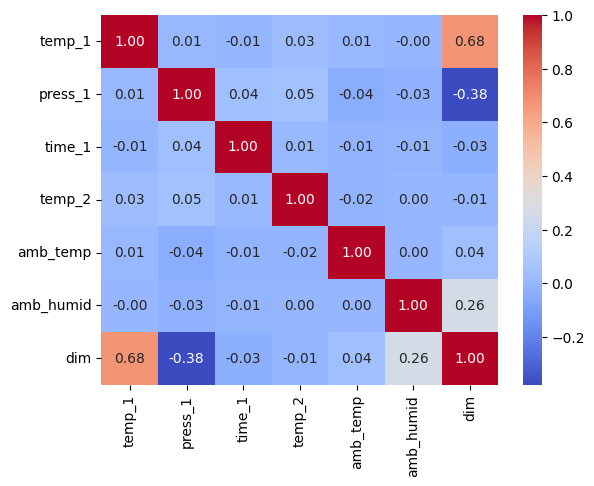

In [10]:
# 1) 상관 히트맵
# 불 필요한 로트 번호는 날려버리고, 나머지 요소들에 대해서 상관관계 확인
data = df.drop(columns='lot_no').corr()
# data
# 더 비주얼적으로 상관관계 확인을 위해
# 수치는 소숫점 2자리로 표기 annot=True, fmt='.2f'
sns.heatmap(data, annot=True, fmt='.2f', cmap='coolwarm')
plt.show()

In [11]:
# 2) 시차별 상관 : 온도를 k 로트 밀었을 때 치수와의 상관
for k in range(0, 8):
    # temp_1 의 k 로트 만큼 밀면서 dim 과의 상관관계 확인
    r = df['temp_1'].shift(k).corr(df['dim'])
    print(f'lag {k} : {r:.3f}')

lag 0 : 0.675
lag 1 : 0.719
lag 2 : 0.763
lag 3 : 0.797
lag 4 : 0.756
lag 5 : 0.712
lag 6 : 0.672
lag 7 : 0.634


### 2-3. [2단계] 특징공학 (Feature Engineering)

In [12]:
def build_features(df): # 원본 데이터(df)를 받아 새로운 특징(변수)들을 반환하는 함수
    f = pd.DataFrame(index=df.index)
    f['temp_1']       = df['temp_1']
    f['temp_1_lag3']  = df['temp_1'].shift(3)   # 3로트 전의 상류 온도 값 매칭
    f['temp_1_ma5']   = df['temp_1'].rolling(5).mean()  # 5개 로트 온도의 이동평균(이때 앞 4개는 NaN)
    f['press_1']      = df['press_1']
    f['time_1']       = df['time_1']
    f['time_dev2']    = (df['time_1'] - 60) ** 2 # 60초에서 멀어질수록 값이 기하급수적으로 커짐(이탈을 쉽게 파악)
    f['temp_2']       = df['temp_2']
    f['amb_temp']     = df['amb_temp']
    f['amb_humid']    = df['amb_humid']
    # 3로트 전 온도 기준(180)과 현재 습도가 기준(50)이 벗어난 정도를 곱한다.
    # 두 조건이 동시에 크게 어긋날 때 치수에 미치는 복합적인 영향을 모델에 알려준다.
    f['temp_x_humid'] = (f['temp_1_lag3'] - 180) * (df['amb_humid'] - 50)
    # 3로트전 온도 매칭, 이동평균추가, 특정 치수 틀어짐을 강력하게 표현
    return f

In [13]:
X = build_features(df)
y = df['dim']
# 모든 컬럼(axis=1)에 빈칸이 하나도 없는 행만 True로 표시하는 필터(mask) 생성
mask = X.notna().all(axis=1)
# 결측치 없는 값만 각각 넣어준다.
X, y = X[mask], y[mask]

### 2-4. [3단계] 회귀모델 학습 · 비교

In [ ]:
!pip install xgboost
from sklearn.model_selection import cross_validate, KFold, TimeSeriesSplit
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor

In [15]:
# 모델 정의
models = {
    'Linear':LinearRegression(),
    'RandomForest':RandomForestRegressor(n_estimators=300, random_state=0),
    'XGBoost':XGBRegressor(n_estimators=500, learning_rate=0.05,max_depth=4, random_state=0),
}
# 교차검증
cv = KFold(n_splits=5, shuffle=True, random_state=0)
# 시간 순서를 지켜야 하면 : cv = TimeSeriesSplit(n_splits=5)

In [16]:
rows = []
for name, model in models.items():
    # scoring : 채점 기준 -> tuple 안에 여러개를 넣을 수 있다.
    # neg_root_mean_squared_error : 음수 RMSE(평균 제곱근 오차)
    # -> scikit-learn 에서는 클수록 좋다는 규칙이 있는데, RMSE 는 작을수록 좋다. 그래서 반전을 위해 음수 사용
    # r2 : 우리 모델이 몇 퍼센트(%)나 똑똑하게 설명해 냈는지
    r = cross_validate(model, X, y, cv=cv, scoring=('neg_root_mean_squared_error', 'r2'))
    # 각 Fold의 학습이 아닌 검증 점수가 필요 하므로 test_ 항목에서 가져옴
    rows.append({'model': name,
                 # test_neg_root_mean_squared_error 의 평균에 - 값을 다시 양으로 변경
                 'RMSE(mm)': -r['test_neg_root_mean_squared_error'].mean(),
                 # r2 값 평균
                 'R2': r['test_r2'].mean()})

result = pd.DataFrame(rows).sort_values('RMSE(mm)')
print(result)          # → 성능비교표 (산출물)

          model  RMSE(mm)        R2
0        Linear  0.004025  0.934886
2       XGBoost  0.004675  0.912121
1  RandomForest  0.005072  0.896720


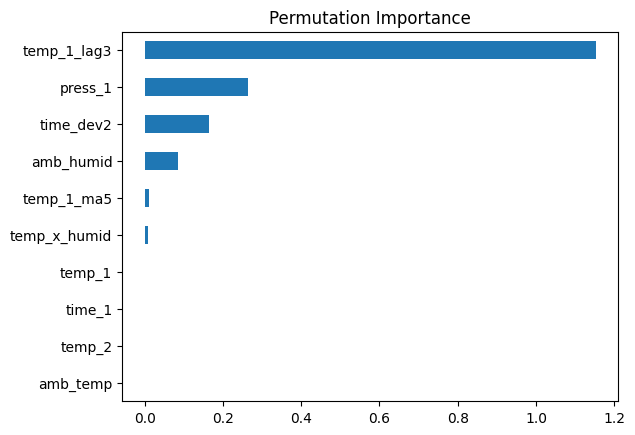

In [17]:
# 특징 중요도 해석
from sklearn.inspection import permutation_importance
from sklearn.model_selection import train_test_split

# 데이터 분할
x_train, x_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=0)

# 모델 학습
model = XGBRegressor(n_estimators=500, learning_rate=0.05, max_depth=4,random_state=0)
best = model.fit(x_train, y_train)

# permutation_importance: 변수 값을 무작위로 섞어 중요도를 계산해 주는 함수
# n_repeats=10: 각 특성마다 무작위 섞기를 10번씩 반복
pi = permutation_importance(best, x_test, y_test, n_repeats=10, random_state=0)

# pi.importances_mean:모델 성능(R2)이 평균적으로 얼마나 떨어졌는지를 담은 배열
# index=X.columns 입력 데이터프레임 X가 가지고 있는 컬럼 이름 목록을 붙임
# sort_values() : 정렬
imp = pd.Series(pi.importances_mean, index=X.columns).sort_values()
imp.plot.barh(title='Permutation Importance')
plt.show()

In [ ]:
# 다음에 모델 활용을 하고 싶다면?
# from joblib import dump
# 학습한 알고리즘을 저장하여 다른 곳에서 사용할 수도 있다.
# dump(best, '/content/data/best.joblib')

### 2-5. [4단계] 규격 대비 위험 근접 판정
| 순위 | 모델 (model) | RMSE (mm) | R² |
| :---: | :--- | :---: | :---: |
| 1 | Linear | 0.004025 | 0.934886 |
| 2 | XGBoost | 0.004675 | 0.912121 |
| 3 | RandomForest | 0.005072 | 0.896720 |

In [18]:
# 목표값, 규격하한, 규격상한
SV, LSL, USL = 10.00, 9.95, 10.05
# 공차의 중간점 지정
half_tol = (USL - LSL) / 2

# 이전 도출한 내용과 모델을 활용한다.
# model : XGBoost | RMSE : 0.004675 | R2:0.912121
rmse = 0.004675
x_train, x_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=0)
pred = best.predict(x_test) # 제품 치수 예측값

In [19]:
# 예측값, 실제값
risk = pd.DataFrame({'pred': pred, 'actual': y_test.values}, index=x_test.index)

# 예측값이 목표값(SV) 10 에 얼마나 떨어진지를 구해 공차 중앙점과 얼마나 차이가 나는지...
risk['proximity'] = (risk['pred'] - SV).abs() / half_tol # Proximity : 근접

# 예측값에 모델 오차 2배(2 * rmse)를 더했을 때 상한 규격(USL)10.05 를 초과하는지 확인
# 예측값에 모델 오차 2배(2 * rmse)를 더뺐을 때 하한 규격(LSL)9.95 미만인지 확인
# 둘 중하나라도 해당되면 True
risk['out_band']  = (risk['pred'] + 2 * rmse > USL) | (risk['pred'] - 2 * rmse < LSL)

# select([조건리스트],[조건1 대응값,조건2 대응값],기본값)
risk['grade'] = np.select(
    [risk['out_band'] | (risk['proximity'] >= 0.8), risk['proximity'] >= 0.6],
    ['위험', '주의'], default='정상')

print(risk['grade'].value_counts())

grade
정상    573
주의     25
위험      1
Name: count, dtype: int64


### 2-6. [5단계] 파라미터 조정 권고안

In [ ]:
import numpy as np
# 후보 설정
# 압력 : 4.6 bar ~ 5.4 bar까지 0.05 단위로 쪼갠 수치
# 유지시간 : 56 ~ 64 까지 0.5 단위로 쪼갠 수치
GRID = {
    'press_1': np.round(np.arange(4.6, 5.41, 0.05), 2),   # 설비 허용 범위
    'time_1' : np.arange(56, 64.1, 0.5),
}
# GRID

{'press_1': array([4.6 , 4.65, 4.7 , 4.75, 4.8 , 4.85, 4.9 , 4.95, 5.  , 5.05, 5.1 ,
        5.15, 5.2 , 5.25, 5.3 , 5.35, 5.4 ]),
 'time_1': array([56. , 56.5, 57. , 57.5, 58. , 58.5, 59. , 59.5, 60. , 60.5, 61. ,
        61.5, 62. , 62.5, 63. , 63.5, 64. ])}

In [22]:
import itertools
def recommend(x_row, model):
    cands = []

    # 압력과 유지시간을 모든 경우의 수로 짝을 지어 하나씩 꺼내 반복문을 돌린다.
    for p, t in itertools.product(GRID['press_1'], GRID['time_1']):
        # 받아온 row 를 복사하여 x 에 담는다.(원본보존)
        x = x_row.copy()
        # x['press_1'], x['time_1'] = p, t: 압력과 유지시간을 가상 후보값 (p, t)로 대입
        x['press_1'], x['time_1'] = p, t
        # 유지시간이 짧고나 길수록 치수 편차가 커진다.(그래서 이에 대한 내용을 추가)
        x['time_dev2'] = (t - 60) ** 2   
        # 데이터상 압력은(4.6 ~ 5.4 bar) 안에서는 압력이 올라갈수록 치수가 일관되게 줄어드는 선형적(직선적) 경향이 있어서 아래 코드를 굳이 넣을 필요가 없다.    
        # x['press_dev2'] = (p - 60) ** 2
           
        cands.append(x)
    cands = pd.DataFrame(cands)

    # 예측하고, SV 와의 절대값 차이를 계산하여 gap 컬럼 에 추가
    cands['pred'] = model.predict(cands[X.columns])
    cands['gap'] = (cands['pred'] - SV).abs()    
  
    p_change = (cands['press_1'] - x_row['press_1']).abs() # 압력의 변화량
    t_change = (cands['time_1'] - x_row['time_1']).abs() # 시간의 변화량
    # 서로 단위가 다르므로 0.2 bar 변화와 2초 변화를 동등한 1단위로 맞추어(정규화) 더해 준다.
    cands['change'] = (p_change/0.2) + (t_change/2)

    # 변경량이 작은 안을 우선 (현장 수용성 - 현장에서도 많이 바꾸는거 안좋아함)
    # 차이와 변화량이 작은 것을 우선적으로 정렬
    return cands.sort_values(['gap', 'change']).head(3)

In [23]:
risk[risk['grade'] == '위험']

,pred,actual,proximity,out_band,grade
1596,9.951326,9.946295,0.973473,True,위험


In [27]:
#  SV 10.00mm, LSL 9.95mm, USL 10.05mm
for idx in risk[risk['grade'] == '위험'].index[:3]:
    print(f"Lot {idx}(위험등급 판정) - 예상수치: {risk.loc[idx, 'pred']:.4f}mm")
    # print(recommend(x_test.loc[idx],best))
    print(recommend(x_test.loc[idx], best)[['press_1', 'time_1', 'pred', 'gap']].to_string(index=False))

Lot 1596(위험등급 판정) - 예상수치: 9.9513mm
 press_1  time_1     pred      gap
    4.65    64.0 9.985416 0.014584
    4.60    64.0 9.985360 0.014640
    4.70    64.0 9.985057 0.014943
